# Chapter 4: QR Decomposition and Numerical Rank — Coding Lab (`proj.ipynb`)

**Mathematics for AI and Machine Learning** ([math4ai.org](https://math4ai.org))  
*Author: Henry Fuheng Wu*

This interactive notebook implements every theoretical result, algorithm, and exercise from **Chapter 4 (QR Decomposition and Numerical Rank)** using **NumPy**, **PyTorch**, and **Matplotlib**:
1. **Part 1 — Feature Redundancy, Gram–Schmidt QR & Staircase Coordinates (Exercises 1–3)**: Gram matrix rank $\operatorname{rank}(X^\top X) = \operatorname{rank}(X)$, rank-revealing Gram–Schmidt QR from scratch, generalized upper triangular staircase $R$, and column-space coordinate reconstruction.
2. **Part 2 — Numerical Rank, Tolerance Thresholds & Stable Rank (Exercise 4)**: Comparing QR diagonal thresholds $|r_{ii}| > \epsilon\|A\|_F$, singular value thresholds $\sigma_k \ge \epsilon\sigma_0$, smooth stable rank $\|A\|_F^2 / \|A\|_2^2$, and noise amplification in nearly collinear regression.
3. **Part 3 — Orthonormal Rank Preservation & Kernel Gram Matrices (Exercises 5 & 6)**: Verifying $\operatorname{rank}(QA) = \operatorname{rank}(AQ^\top) = \operatorname{rank}(R) = \operatorname{rank}(A)$, singular spectrum invariance, $K = XX^\top = Q(RR^\top)Q^\top$, and Kernel Ridge Regression $(K + \lambda I)\boldsymbol\alpha = \mathbf{y}$.
4. **Part 4 — Householder Reflections, Full Householder QR & Stability Benchmark (Exercise 7 & Deep Dive)**: Constructing $H_0 = I - 2\hat{\mathbf{v}}\hat{\mathbf{v}}^\top$, full Householder QR, and benchmarking Classical Gram–Schmidt (CGS) vs. Modified Gram–Schmidt (MGS) vs. Householder QR on ill-conditioned Hilbert matrices.
5. **Part 5 — Rank-1 Perturbations $T = I - \beta\mathbf{u}\mathbf{u}^\top$ & Sherman–Morrison Inverse (Exercise 8)**: Spectral analysis of $T(\beta)$ as $\beta$ transitions through identity ($\beta=0$), projection ($\beta=1$), and reflection ($\beta=2$), plus the Sherman–Morrison inverse.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
torch.manual_seed(42)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"]
print(f"NumPy: {np.__version__} | PyTorch: {torch.__version__}")

NumPy: 2.4.6 | PyTorch: 2.10.0+cu128


---
## Part 1: Feature Redundancy, Gram–Schmidt QR & Staircase Coordinates (Exercises 1–3)

- **Exercise 1**: Verify $\operatorname{rank}(M^\top M) = \operatorname{rank}(M)$ for rank-deficient $X = \begin{bmatrix} 1&2&3\\2&4&6\\3&6&9\end{bmatrix}$ ($\operatorname{rank}=1$) and full-column-rank $A = \begin{bmatrix} 1&0&1\\0&1&1\\1&1&0\end{bmatrix}$ ($\operatorname{rank}=3$, $\det A^\top A = 4$) and $B = \begin{bmatrix} 1&2\\3&4\\5&6\end{bmatrix}$ ($\operatorname{rank}=2$, $\det B^\top B = 24$).
- **Exercise 2**: Compute $X = QR$ via Gram–Schmidt on $X = \begin{bmatrix} 1&1&0\\1&0&1\\0&1&1\end{bmatrix}$ ($\operatorname{rank}=3$) and verify $Q^\top Q = I_3$, $QR = X$.
- **Exercise 3**: Compute rank-revealing QR on $X = \begin{bmatrix} 1&2&3\\2&4&6\\1&1&1\end{bmatrix}$ ($\operatorname{rank}=2 < 3$), obtaining thin $Q \in \mathbb{R}^{3\times 2}$ and generalized upper triangular staircase $R \in \mathbb{R}^{2\times 3}$.

In [2]:
# Exercise 1: Feature redundancy and Gram matrix rank
X1 = np.array([[1., 2., 3.], [2., 4., 6.], [3., 6., 9.]])
A1 = np.array([[1., 0., 1.], [0., 1., 1.], [1., 1., 0.]])
B1 = np.array([[1., 2.], [3., 4.], [5., 6.]])

for name, M in [("X", X1), ("A", A1), ("B", B1)]:
    MtM = M.T @ M
    print(f"{name}: shape={M.shape} | rank({name})={np.linalg.matrix_rank(M)} | "
          f"rank({name}^T {name})={np.linalg.matrix_rank(MtM)} | det({name}^T {name})={np.linalg.det(MtM):.1f}")

# Exercise 2: Rank-revealing Gram-Schmidt QR from scratch
def gram_schmidt_qr(A, tol=1e-10):
    """Rank-revealing Gram-Schmidt QR: A (M x N) = Q (M x r) @ R (r x N), r = rank(A)."""
    Q, R = [], np.zeros((A.shape[1], A.shape[1]))
    for n in range(A.shape[1]):
        a = A[:, n].astype(float)
        coeffs = np.array([a @ q for q in Q])
        res = a - sum(c * q for c, q in zip(coeffs, Q)) if Q else a
        R[:len(Q), n] = coeffs
        if np.linalg.norm(res) > tol:
            R[len(Q), n] = np.linalg.norm(res)
            Q.append(res / np.linalg.norm(res))
    return np.column_stack(Q), R[:len(Q)]

X2 = np.array([[1., 1., 0.], [1., 0., 1.], [0., 1., 1.]])
Q2, R2 = gram_schmidt_qr(X2)
Q2_exact = np.array([[1/np.sqrt(2),  1/np.sqrt(6), -1/np.sqrt(3)],
                     [1/np.sqrt(2), -1/np.sqrt(6),  1/np.sqrt(3)],
                     [0.0,           2/np.sqrt(6),  1/np.sqrt(3)]])
R2_exact = np.array([[np.sqrt(2), 1/np.sqrt(2),  1/np.sqrt(2)],
                     [0.0,        np.sqrt(6)/2,  1/np.sqrt(6)],
                     [0.0,        0.0,         2*np.sqrt(3)/3]])
print("\nExercise 2 checks -> Q matches exact:", np.allclose(Q2, Q2_exact),
      "| R matches exact:", np.allclose(R2, R2_exact),
      "| Q^T Q == I_3:", np.allclose(Q2.T @ Q2, np.eye(3)),
      "| Q @ R == X2:", np.allclose(Q2 @ R2, X2))

X: shape=(3, 3) | rank(X)=1 | rank(X^T X)=1 | det(X^T X)=0.0
A: shape=(3, 3) | rank(A)=3 | rank(A^T A)=3 | det(A^T A)=4.0
B: shape=(3, 2) | rank(B)=2 | rank(B^T B)=2 | det(B^T B)=24.0

Exercise 2 checks -> Q matches exact: True | R matches exact: True | Q^T Q == I_3: True | Q @ R == X2: True


Exercise 3 -> Q3 shape: (3, 2) | R3 shape: (2, 3)
R3 (generalized upper triangular):
 [[2.4495 4.4907 6.532 ]
 [0.     0.9129 1.8257]]
Reconstructed col 2 from R3[:, 2]: [3. 6. 1.] vs exact: [3. 6. 1.]
Null vector v = [1, -2, 1]^T -> X3 @ v = [0. 0. 0.]


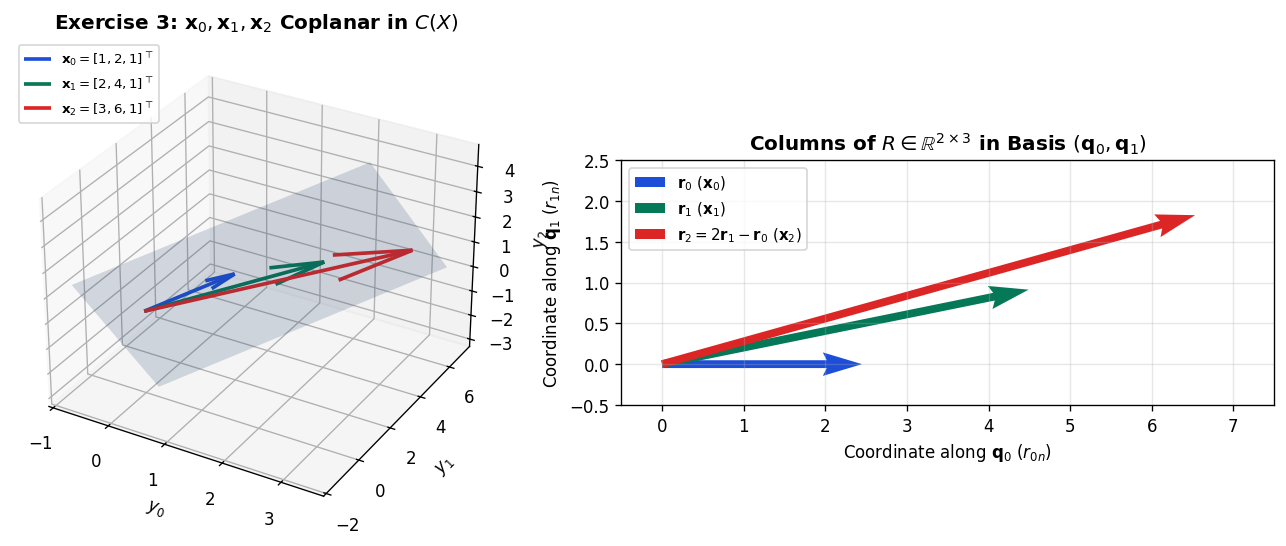

In [3]:
# Exercise 3: Rank-deficient least squares & staircase R in R^{2 x 3}
X3 = np.array([[1., 2., 3.],
               [2., 4., 6.],
               [1., 1., 1.]])
Q3, R3 = gram_schmidt_qr(X3)
print("Exercise 3 -> Q3 shape:", Q3.shape, "| R3 shape:", R3.shape)
print("R3 (generalized upper triangular):\n", R3)
print("Reconstructed col 2 from R3[:, 2]:", Q3 @ R3[:, 2], "vs exact:", X3[:, 2])
print("Null vector v = [1, -2, 1]^T -> X3 @ v =", X3 @ np.array([1., -2., 1.]))

# Visualize 3D Column Space Plane C(X3) = span{q0, q1} and vectors x0, x1, x2
fig = plt.figure(figsize=(11.5, 4.6))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
s_grid, t_grid = np.meshgrid(np.linspace(-1, 7, 12), np.linspace(-2, 3, 12))
plane_pts = (s_grid[..., None] * Q3[:, 0] + t_grid[..., None] * Q3[:, 1])
ax1.plot_surface(plane_pts[..., 0], plane_pts[..., 1], plane_pts[..., 2], color="#2b548a", alpha=0.18)
colors = ["#1d4ed8", "#047857", "#dc2626"]
for idx, col_label in enumerate([r"$\mathbf{x}_0=[1,2,1]^\top$", r"$\mathbf{x}_1=[2,4,1]^\top$", r"$\mathbf{x}_2=[3,6,1]^\top$"]):
    v = X3[:, idx]
    ax1.quiver(0, 0, 0, v[0], v[1], v[2], color=colors[idx], lw=2.2, label=col_label)
ax1.set_title(r"Exercise 3: $\mathbf{x}_0, \mathbf{x}_1, \mathbf{x}_2$ Coplanar in $C(X)$", fontweight="bold")
ax1.set_xlabel("$y_0$"); ax1.set_ylabel("$y_1$"); ax1.set_zlabel("$y_2$")
ax1.legend(loc="upper left", fontsize=8)

# Right panel: Coordinates of x0, x1, x2 in the 2D orthonormal basis (q0, q1)
ax2 = fig.add_subplot(1, 2, 2)
for idx, lbl in enumerate([r"$\mathbf{r}_0$ ($\mathbf{x}_0$)", r"$\mathbf{r}_1$ ($\mathbf{x}_1$)", r"$\mathbf{r}_2 = 2\mathbf{r}_1 - \mathbf{r}_0$ ($\mathbf{x}_2$)"]):
    ax2.quiver(0, 0, R3[0, idx], R3[1, idx], angles="xy", scale_units="xy", scale=1, color=colors[idx], width=0.012, label=lbl)
ax2.set_xlim(-0.5, 7.5); ax2.set_ylim(-0.5, 2.5); ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)
ax2.set_xlabel(r"Coordinate along $\mathbf{q}_0$ ($r_{0n}$)")
ax2.set_ylabel(r"Coordinate along $\mathbf{q}_1$ ($r_{1n}$)")
ax2.set_title(r"Columns of $R \in \mathbb{R}^{2 \times 3}$ in Basis $(\mathbf{q}_0, \mathbf{q}_1)$", fontweight="bold")
ax2.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

---
## Part 2: Numerical Rank, Tolerance Thresholds & Stable Rank (Exercise 4)

In **Exercise 4**, we compare exact rank against tolerance-based numerical rank ($|r_{ii}| > \epsilon\|M\|_F$ or $\sigma_k \ge \epsilon\sigma_0$) and tolerance-free **stable rank** $\operatorname{srank}(M) = \|M\|_F^2 / \|M\|_2^2$ on:
$$A = \begin{bmatrix} 1 & 2 & 2.0001 \\ 2 & 4 & 4.0002 \\ 3 & 6 & 6.0003 \end{bmatrix}, \qquad B = \begin{bmatrix} 1 & 1.001 \\ 1 & 1.002 \\ 1 & 1.003 \end{bmatrix}.$$

Matrix A: ||A||_F = 11.2252 | |diag(R)| = [3.7417 0.     0.    ] | singular values = [11.2252  0.      0.    ]
   eps=1e-05 -> threshold eps*||A||_F=0.000112 | QR rank=1 | SVD rank=1
   eps=1e-04 -> threshold eps*||A||_F=0.001123 | QR rank=1 | SVD rank=1
   eps=1e-03 -> threshold eps*||A||_F=0.011225 | QR rank=1 | SVD rank=1
   eps=1e-02 -> threshold eps*||A||_F=0.112252 | QR rank=1 | SVD rank=1
   Tolerance-free stable rank srank(A) = 1.000000

Matrix B: ||B||_F = 2.4519 | |diag(R)| = [1.7321 0.0014] | singular values = [2.4519 0.001 ]
   eps=1e-05 -> threshold eps*||B||_F=0.000025 | QR rank=2 | SVD rank=2
   eps=1e-04 -> threshold eps*||B||_F=0.000245 | QR rank=2 | SVD rank=2
   eps=1e-03 -> threshold eps*||B||_F=0.002452 | QR rank=1 | SVD rank=1
   eps=1e-02 -> threshold eps*||B||_F=0.024519 | QR rank=1 | SVD rank=1
   Tolerance-free stable rank srank(B) = 1.000000



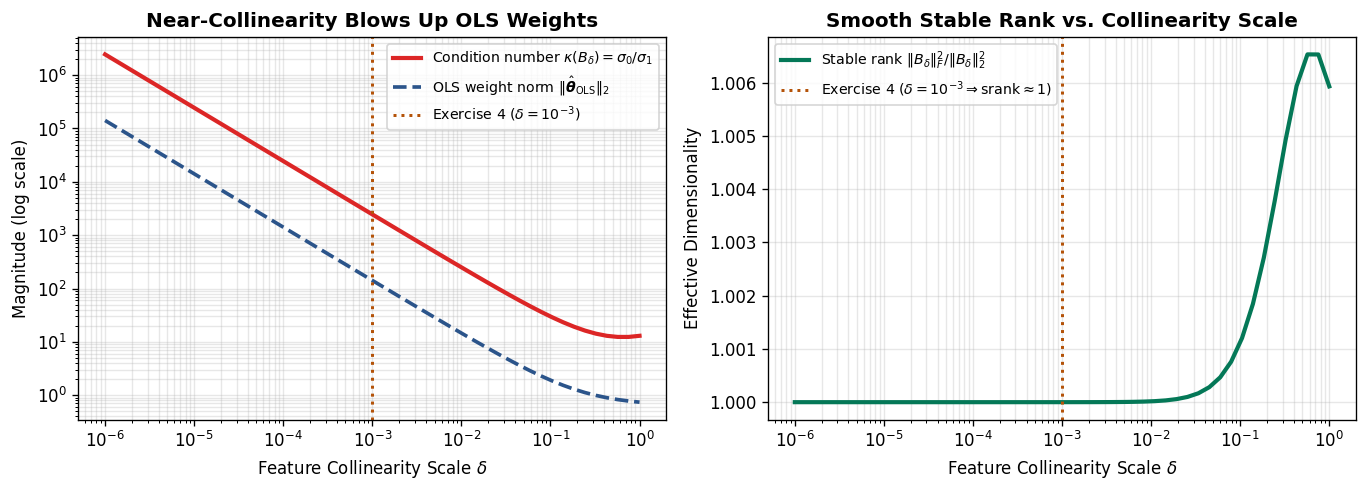

In [4]:
# Exercise 4: Numerical Rank vs Exact Rank and Stable Rank
A4 = np.array([[1., 2., 2.0001],
               [2., 4., 4.0002],
               [3., 6., 6.0003]])
B4 = np.array([[1., 1.001],
               [1., 1.002],
               [1., 1.003]])

for name, M in [("A", A4), ("B", B4)]:
    _, R_m = np.linalg.qr(M)
    r_diag = np.abs(np.diag(R_m))
    frob = np.linalg.norm(M, "fro")
    s = np.linalg.svd(M, compute_uv=False)
    srank = (s ** 2).sum() / (s[0] ** 2)
    print(f"Matrix {name}: ||{name}||_F = {frob:.4f} | |diag(R)| = {np.round(r_diag, 6)} | singular values = {np.round(s, 6)}")
    for eps in [1e-5, 1e-4, 1e-3, 1e-2]:
        nr_qr  = int(np.sum(r_diag > eps * frob))
        nr_svd = int(np.sum(s >= eps * s[0]))
        print(f"   eps={eps:.0e} -> threshold eps*||{name}||_F={eps*frob:.6f} | QR rank={nr_qr} | SVD rank={nr_svd}")
    print(f"   Tolerance-free stable rank srank({name}) = {srank:.6f}\n")

# Visualize numerical rank transition & OLS weight explosion as collinearity delta -> 0
deltas = np.logspace(-6, 0, 50)
conds, sranks, weight_norms = [], [], []
y_target = np.array([1.0, -0.5, 0.8])
for d_val in deltas:
    B_delta = np.array([[1.0, 1.0 + 1*d_val],
                        [1.0, 1.0 + 2*d_val],
                        [1.0, 1.0 + 3*d_val]])
    s_d = np.linalg.svd(B_delta, compute_uv=False)
    conds.append(s_d[0] / s_d[1])
    sranks.append((s_d**2).sum() / s_d[0]**2)
    w_ols = np.linalg.lstsq(B_delta, y_target, rcond=None)[0]
    weight_norms.append(np.linalg.norm(w_ols))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.loglog(deltas, conds, color="#dc2626", lw=2.5, label=r"Condition number $\kappa(B_\delta) = \sigma_0/\sigma_1$")
ax1.loglog(deltas, weight_norms, color="#2b548a", lw=2.2, ls="--", label=r"OLS weight norm $\|\hat{\boldsymbol{\theta}}_{\mathrm{OLS}}\|_2$")
ax1.axvline(1e-3, color="#b45309", ls=":", lw=1.8, label=r"Exercise 4 ($\delta = 10^{-3}$)")
ax1.set_xlabel(r"Feature Collinearity Scale $\delta$")
ax1.set_ylabel("Magnitude (log scale)")
ax1.set_title("Near-Collinearity Blows Up OLS Weights", fontweight="bold")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(loc="upper right", fontsize=8.5)

ax2.semilogx(deltas, sranks, color="#047857", lw=2.5, label=r"Stable rank $\|B_\delta\|_F^2 / \|B_\delta\|_2^2$")
ax2.axvline(1e-3, color="#b45309", ls=":", lw=1.8, label=r"Exercise 4 ($\delta = 10^{-3} \Rightarrow \mathrm{srank}\approx 1$)")
ax2.set_xlabel(r"Feature Collinearity Scale $\delta$")
ax2.set_ylabel("Effective Dimensionality")
ax2.set_title("Smooth Stable Rank vs. Collinearity Scale", fontweight="bold")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Part 3: Orthonormal Rank Preservation & Kernel Gram Matrices (Exercises 5 & 6)

- **Exercise 5**: Verify $\operatorname{rank}(QA) = \operatorname{rank}(AQ^\top) = \operatorname{rank}(R) = \operatorname{rank}(A)$ and singular spectrum invariance.
- **Exercise 6**: For $X = \begin{bmatrix} 1&2\\3&4\\5&6\end{bmatrix} \in \mathbb{R}^{3\times 2}$, verify $\operatorname{rank}(XX^\top) = \operatorname{rank}(X) = 2$, $K = Q(RR^\top)Q^\top$, and Kernel Ridge Regression $(K + \lambda I_N)\boldsymbol\alpha = \mathbf{y}$.

In [5]:
# Exercise 5: Rank & singular spectrum preservation under orthonormal transformations
A5 = np.array([[1., 2., 3.], [2., 4., 6.]])
Q5 = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)
_, R5 = gram_schmidt_qr(A5)

print("Exercise 5 -> sqrt(2) * Q5 @ A5:\n", np.round(np.sqrt(2) * (Q5 @ A5), 4))
print("rank(A5), rank(Q5 @ A5), rank(R5):",
      np.linalg.matrix_rank(A5), np.linalg.matrix_rank(Q5 @ A5), np.linalg.matrix_rank(R5))

# Exercise 6: Kernel Gram matrix K = X X^T and Kernel Ridge Regression
X6 = np.array([[1., 2.], [3., 4.], [5., 6.]])
K6 = X6 @ X6.T
Q6, R6 = gram_schmidt_qr(X6)

print("\nExercise 6 -> K = X X^T:\n", K6.astype(int))
print("rank(X6), rank(K6), rank(R6):",
      np.linalg.matrix_rank(X6), np.linalg.matrix_rank(K6), np.linalg.matrix_rank(R6))
print("det(K6):                ", round(np.linalg.det(K6), 8))
print("K6 == Q6 (R6 R6^T) Q6^T:", np.allclose(K6, Q6 @ (R6 @ R6.T) @ Q6.T))

# Kernel Ridge Regression vs Primal Ridge Regression
y6 = np.array([1.0, 2.5, 3.8])
lam6 = 0.5
alpha_krr = np.linalg.solve(K6 + lam6 * np.eye(3), y6)
theta_rr  = np.linalg.solve(X6.T @ X6 + lam6 * np.eye(2), X6.T @ y6)
print("Dual Kernel Ridge fit == Primal Ridge fit:", np.allclose(K6 @ alpha_krr, X6 @ theta_rr))

Exercise 5 -> sqrt(2) * Q5 @ A5:
 [[ 3.  6.  9.]
 [-1. -2. -3.]]
rank(A5), rank(Q5 @ A5), rank(R5): 1 1 1

Exercise 6 -> K = X X^T:
 [[ 5 11 17]
 [11 25 39]
 [17 39 61]]
rank(X6), rank(K6), rank(R6): 2 2 2
det(K6):                 0.0
K6 == Q6 (R6 R6^T) Q6^T: True
Dual Kernel Ridge fit == Primal Ridge fit: True


---
## Part 4: Householder Reflections, Full Householder QR & Stability Benchmark (Exercise 7 & Deep Dive)

In **Exercise 7**, we construct the Householder reflection $H_0 = I - 2\hat{\mathbf{v}}\hat{\mathbf{v}}^\top$ that zeros out the subdiagonal entries of the first column of:
$$A = \begin{bmatrix} 1 & 2 & 3 \\ 2 & 3 & 4 \\ 3 & 4 & 5 \\ 4 & 5 & 6 \end{bmatrix} \in \mathbb{R}^{4 \times 3},$$
verify $H_0^\top = H_0$, $H_0^\top H_0 = I_4$, $H_0^2 = I_4$, and then benchmark **Classical Gram–Schmidt (CGS)**, **Modified Gram–Schmidt (MGS)**, and **Householder QR** on ill-conditioned Hilbert matrices.

First column of H0 @ A7: [ 5.4772 -0.     -0.     -0.    ] (sqrt(30) = 5.477226 )
Symmetric:  True | Orthogonal: True | Involutory: True | det(H0): -1.0
Full Householder R on A7:
 [[-5.4772 -7.303  -9.1287]
 [-0.     -0.8165 -1.633 ]
 [ 0.     -0.      0.    ]
 [ 0.     -0.     -0.    ]]
Q @ R == A7: True


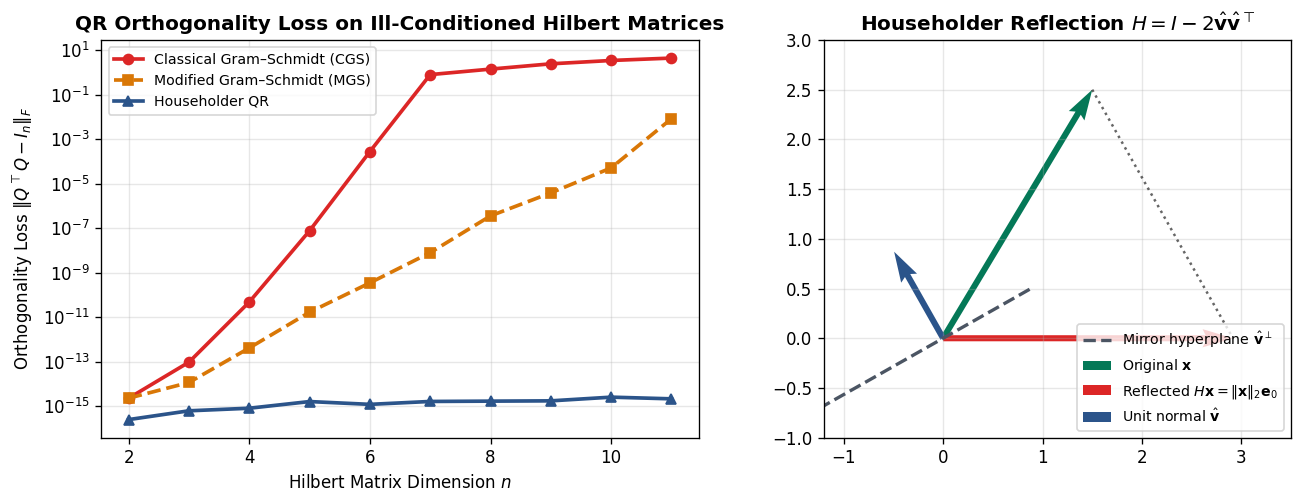

In [6]:
# Exercise 7: Householder reflection H0 and full Householder QR
A7 = np.array([[1., 2., 3.],
               [2., 3., 4.],
               [3., 4., 5.],
               [4., 5., 6.]])
a0 = A7[:, 0]
e0 = np.array([1., 0., 0., 0.])
u7 = a0 - np.linalg.norm(a0) * e0
v_hat7 = u7 / np.linalg.norm(u7)
H0 = np.eye(4) - 2.0 * np.outer(v_hat7, v_hat7)
A7_step1 = H0 @ A7

print("First column of H0 @ A7:", np.round(A7_step1[:, 0], 6), "(sqrt(30) =", round(np.sqrt(30), 6), ")")
print("Symmetric: ", np.allclose(H0, H0.T),
      "| Orthogonal:", np.allclose(H0.T @ H0, np.eye(4)),
      "| Involutory:", np.allclose(H0 @ H0, np.eye(4)),
      "| det(H0):", round(np.linalg.det(H0), 4))

def householder_qr_full(M):
    m, n = M.shape
    R, Q = M.astype(float).copy(), np.eye(m)
    for k in range(min(m - 1, n)):
        x = R[k:, k]
        v = x.copy()
        v[0] += np.copysign(np.linalg.norm(x), x[0])
        if np.linalg.norm(v) > 1e-12:
            v /= np.linalg.norm(v)
            H_k = np.eye(m)
            H_k[k:, k:] -= 2.0 * np.outer(v, v)
            R, Q = H_k @ R, Q @ H_k
    return Q, R

Q_hh7, R_hh7 = householder_qr_full(A7)
print("Full Householder R on A7:\n", np.round(R_hh7, 4))
print("Q @ R == A7:", np.allclose(Q_hh7 @ R_hh7, A7))

# Deep Dive: CGS vs MGS vs Householder QR Orthogonality Loss across Hilbert Matrices H_n
def cgs_and_mgs(M):
    _, n = M.shape
    Q_c, Q_m = M.astype(float).copy(), M.astype(float).copy()
    for j in range(n):
        a_orig = Q_c[:, j].copy()
        for i in range(j):
            Q_c[:, j] -= (a_orig @ Q_c[:, i]) * Q_c[:, i]
        Q_c[:, j] /= np.linalg.norm(Q_c[:, j])
        for i in range(j):
            Q_m[:, j] -= (Q_m[:, j] @ Q_m[:, i]) * Q_m[:, i]
        Q_m[:, j] /= np.linalg.norm(Q_m[:, j])
    return Q_c, Q_m

dims = list(range(2, 12))
err_cgs, err_mgs, err_hh = [], [], []
for n_dim in dims:
    idx = np.arange(n_dim)
    H_mat = 1.0 / (idx[:, None] + idx[None, :] + 1.0)
    Qc, Qm = cgs_and_mgs(H_mat)
    Qh, _  = householder_qr_full(H_mat)
    In = np.eye(n_dim)
    err_cgs.append(np.linalg.norm(Qc.T @ Qc - In, "fro"))
    err_mgs.append(np.linalg.norm(Qm.T @ Qm - In, "fro"))
    err_hh.append(np.linalg.norm(Qh.T @ Qh - In, "fro"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
ax1.semilogy(dims, err_cgs, "o-", color="#dc2626", lw=2.2, label="Classical Gram–Schmidt (CGS)")
ax1.semilogy(dims, err_mgs, "s--", color="#d97706", lw=2.2, label="Modified Gram–Schmidt (MGS)")
ax1.semilogy(dims, err_hh, "^-", color="#2b548a", lw=2.2, label="Householder QR")
ax1.set_xlabel("Hilbert Matrix Dimension $n$")
ax1.set_ylabel(r"Orthogonality Loss $\|Q^\top Q - I_n\|_F$")
ax1.set_title("QR Orthogonality Loss on Ill-Conditioned Hilbert Matrices", fontweight="bold")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(loc="upper left", fontsize=8.5)

# Right panel: 2D Geometric view of Householder reflection
x_2d = np.array([1.5, 2.5])
y_2d = np.array([np.linalg.norm(x_2d), 0.0])
v_2d = x_2d - y_2d; v_2d /= np.linalg.norm(v_2d)
mirror_dir = np.array([-v_2d[1], v_2d[0]])
t_m = np.linspace(-1.0, 3.2, 50)
ax2.plot(t_m * mirror_dir[0], t_m * mirror_dir[1], color="#4b5563", ls="--", lw=2, label=r"Mirror hyperplane $\hat{\mathbf{v}}^\perp$")
ax2.quiver(0, 0, x_2d[0], x_2d[1], angles="xy", scale_units="xy", scale=1, color="#047857", width=0.013, label=r"Original $\mathbf{x}$")
ax2.quiver(0, 0, y_2d[0], y_2d[1], angles="xy", scale_units="xy", scale=1, color="#dc2626", width=0.013, label=r"Reflected $H\mathbf{x} = \|\mathbf{x}\|_2\mathbf{e}_0$")
ax2.quiver(0, 0, v_2d[0], v_2d[1], angles="xy", scale_units="xy", scale=1, color="#2b548a", width=0.013, label=r"Unit normal $\hat{\mathbf{v}}$")
ax2.plot([x_2d[0], y_2d[0]], [x_2d[1], y_2d[1]], "k:", alpha=0.6)
ax2.set_xlim(-1.2, 3.5); ax2.set_ylim(-1.0, 3.0); ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)
ax2.set_title(r"Householder Reflection $H = I - 2\hat{\mathbf{v}}\hat{\mathbf{v}}^\top$", fontweight="bold")
ax2.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Part 5: Rank-1 Perturbations $T = I - \beta\mathbf{u}\mathbf{u}^\top$ & Sherman–Morrison Inverse (Exercise 8)

In **Exercise 8**, we analyze $T(\beta) = I - \beta\mathbf{u}\mathbf{u}^\top$ for unit vector $\mathbf{u} = \frac{1}{\sqrt{3}}[1, 1, 1]^\top \in \mathbb{R}^3$:
- Eigenvalue along $\mathbf{u}$ is $1 - \beta$; eigenvalue on $\mathbf{u}^\perp$ is $1$ (multiplicity $d - 1 = 2$).
- $\det(T) = 1 - \beta$ and $\operatorname{tr}(T) = d - \beta$.
- At $\beta = 1$, $T(1) = I - \mathbf{u}\mathbf{u}^\top$ is the orthogonal projector onto $\mathbf{u}^\perp$ ($\det = 0$, non-invertible); for $\beta \ne 1$, $T(\beta)^{-1} = I + \frac{\beta}{1 - \beta}\mathbf{u}\mathbf{u}^\top$.

3 * T(beta=2):
 [[ 1 -2 -2]
 [-2  1 -2]
 [-2 -2  1]]
T(2) @ u == -u: True | T(2) @ v1 == v1: True | T(2) @ v2 == v2: True


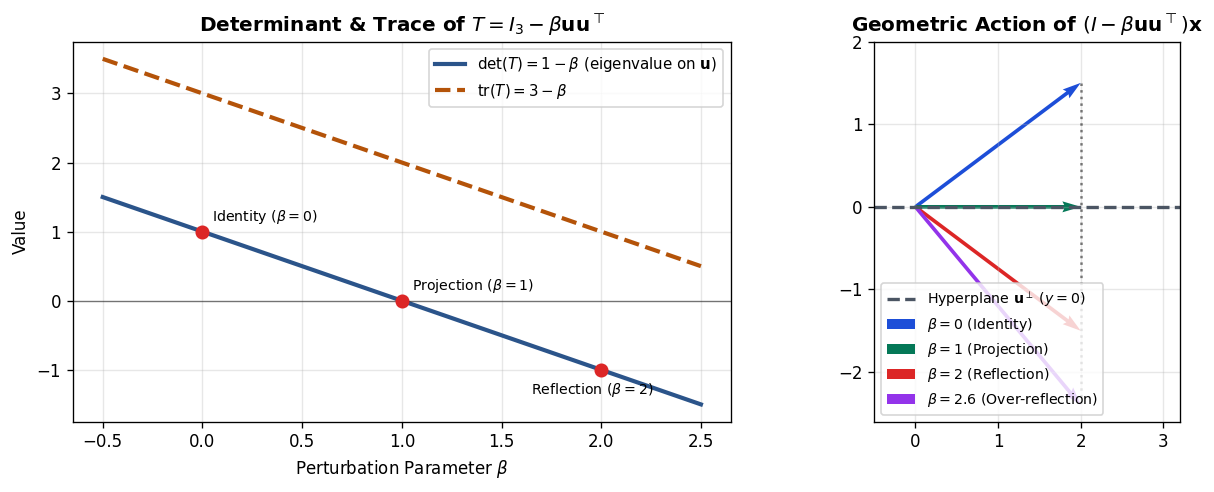

In [7]:
# Exercise 8: Spectral analysis of T = I - beta * u u^T and Sherman-Morrison inverse
u8  = np.ones(3) / np.sqrt(3)
v8_1 = np.array([1., -1.,  0.])
v8_2 = np.array([1.,  0., -1.])

T_beta2 = np.eye(3) - 2.0 * np.outer(u8, u8)
print("3 * T(beta=2):\n", np.round(3 * T_beta2).astype(int))
print("T(2) @ u == -u:", np.allclose(T_beta2 @ u8, -u8),
      "| T(2) @ v1 == v1:", np.allclose(T_beta2 @ v8_1, v8_1),
      "| T(2) @ v2 == v2:", np.allclose(T_beta2 @ v8_2, v8_2))

betas = np.linspace(-0.5, 2.5, 100)
dets  = [np.linalg.det(np.eye(3) - b * np.outer(u8, u8)) for b in betas]
trs   = [np.trace(np.eye(3) - b * np.outer(u8, u8)) for b in betas]

# Visualize determinant/trace vs beta and 2D geometric action of (I - beta u u^T)x
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.plot(betas, dets, color="#2b548a", lw=2.5, label=r"$\det(T) = 1 - \beta$ (eigenvalue on $\mathbf{u}$)")
ax1.plot(betas, trs, color="#b45309", lw=2.5, ls="--", label=r"$\mathrm{tr}(T) = 3 - \beta$")
ax1.axhline(0, color="k", lw=0.8, alpha=0.5)
ax1.scatter([0, 1, 2], [1, 0, -1], color="#dc2626", zorder=5, s=55)
ax1.annotate("Identity ($\\beta=0$)", (0.05, 1.15), fontsize=8.5)
ax1.annotate("Projection ($\\beta=1$)", (1.05, 0.15), fontsize=8.5)
ax1.annotate("Reflection ($\\beta=2$)", (1.65, -1.35), fontsize=8.5)
ax1.set_xlabel(r"Perturbation Parameter $\beta$")
ax1.set_ylabel("Value")
ax1.set_title(r"Determinant & Trace of $T = I_3 - \beta\mathbf{u}\mathbf{u}^\top$", fontweight="bold")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper right", fontsize=9)

# Panel 2: 2D action of T(beta)x for beta in {0, 0.5, 1, 2, 2.5}
u_2d = np.array([0.0, 1.0])              # vertical unit normal u
x_in = np.array([2.0, 1.5])
ax2.axhline(0, color="#4b5563", lw=2, ls="--", label=r"Hyperplane $\mathbf{u}^\perp$ ($y=0$)")
for b_val, col, lbl in [(0.0, "#1d4ed8", r"$\beta=0$ (Identity)"),
                        (1.0, "#047857", r"$\beta=1$ (Projection)"),
                        (2.0, "#dc2626", r"$\beta=2$ (Reflection)"),
                        (2.6, "#9333ea", r"$\beta=2.6$ (Over-reflection)")]:
    tx = (np.eye(2) - b_val * np.outer(u_2d, u_2d)) @ x_in
    ax2.quiver(0, 0, tx[0], tx[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012, label=lbl)
ax2.plot([2.0, 2.0], [1.5, -2.4], "k:", alpha=0.5)
ax2.set_xlim(-0.5, 3.2); ax2.set_ylim(-2.6, 2.0); ax2.set_aspect("equal")
ax2.grid(True, alpha=0.3)
ax2.set_title(r"Geometric Action of $(I - \beta\mathbf{u}\mathbf{u}^\top)\mathbf{x}$", fontweight="bold")
ax2.legend(loc="lower left", fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Summary & Alignment with Chapter 4

| Topic / Exercise | Mathematical Identity | AI / ML Takeaway |
|---|---|---|
| **Ex 1: Gram Matrix Rank** | $\operatorname{rank}(X^\top X) = \operatorname{rank}(X)$ | Normal equations are invertible iff features are linearly independent |
| **Ex 2: Gram–Schmidt QR** | $X = QR$, $Q^\top Q = I_r$, $r_{ii} > 0$ | Extracts an orthonormal basis for the feature column space $C(X)$ |
| **Ex 3: Staircase QR** | $Q \in \mathbb{R}^{M\times r}$, generalized upper triangular $R \in \mathbb{R}^{r\times N}$ | Flat staircase steps in $R$ flag redundant features and give their basis coordinates |
| **Ex 4: Numerical & Stable Rank** | $\operatorname{rank}_\epsilon(A) = \#\{\sigma_k \ge \epsilon\sigma_0\}$, $\operatorname{srank}(A) = \|A\|_F^2 / \|A\|_2^2$ | Diagnoses near-collinearity and overfitting risk before inverting $X^\top X$ |
| **Ex 5: Orthonormal Factors** | $\operatorname{rank}(QA) = \operatorname{rank}(AQ^\top) = \operatorname{rank}(R) = \operatorname{rank}(A)$ | Orthonormal layers preserve singular value spectra and effective dimensionality |
| **Ex 6: Kernel Gram Matrices** | $K = XX^\top = Q(RR^\top)Q^\top$, $(K + \lambda I_N)\boldsymbol\alpha = \mathbf{y}$ | When $N > d$, $K$ is singular; $+\lambda I_N$ lifts zero eigenvalues for Kernel Ridge |
| **Ex 7: Householder QR** | $H = I - 2\hat{\mathbf{v}}\hat{\mathbf{v}}^\top$, $H^\top = H = H^{-1}$ | Backward-stable QR without Gram–Schmidt cancellation error |
| **Ex 8: Rank-1 Perturbations** | $T = I - \beta\mathbf{u}\mathbf{u}^\top$, $\det(T) = 1-\beta$, $\operatorname{tr}(T) = d-\beta$ | Single scalar $\beta$ interpolates between identity ($0$), projection ($1$), and reflection ($2$) |